In [ ]:
!ls -R /content/dataset | head -n 20

/content/dataset:
data.yaml
__MACOSX
PlantProject

/content/dataset/__MACOSX:
PlantProject

/content/dataset/__MACOSX/PlantProject:
test
train
valid

/content/dataset/__MACOSX/PlantProject/test:
images
labels

/content/dataset/__MACOSX/PlantProject/test/images:

/content/dataset/__MACOSX/PlantProject/test/labels:


In [ ]:
import yaml


data_config = {
    'path': '/content/dataset/PlantProject',
    'train': 'train/images',    
    'val': 'valid/images',      
    'test': 'test/images',      
    'nc': 30,                   
    'names': [
        'Banana_Healthy', 'Banana_Sigatoka', 'Chilli_Healthy',
        'Chilli_Anthracnose', 'Radish_Healthy'
        
    ]
}


while len(data_config['names']) < 30:
    data_config['names'].append(f"Class_{len(data_config['names'])}")

with open('/content/dataset/data.yaml', 'w') as f:
    yaml.dump(data_config, f)

print("✅ data.yaml updated with the correct 'PlantProject' and 'valid' paths!")

✅ data.yaml updated with the correct 'PlantProject' and 'valid' paths!


In [ ]:
import os
val_path = "/content/dataset/PlantProject/valid/images"
if os.path.exists(val_path):
    files = os.listdir(val_path)
    print(f"✅ Success! Found {len(files)} images in the validation folder.")
else:
    print(f"❌ Error: {val_path} still doesn't exist. Check folder names again.")

✅ Success! Found 4374 images in the validation folder.


In [ ]:
# --- STEP 1: INSTALL & IMPORTS ---
!pip install ultralytics -U
import os
import yaml
from ultralytics import YOLO
from google.colab import drive


drive.mount('/content/drive', force_remount=True)

# --- STEP 2: CLEAN & UNZIP ---
!rm -rf /content/dataset
!mkdir -p /content/dataset

zip_path = "/content/drive/MyDrive/PlantFileDataset/PlantProject.zip"
!unzip -q "{zip_path}" -d /content/dataset

# --- STEP 3: PATH FIXES ---
class_names = [
    'Banana_Healthy', 'Banana_Sigatoka', 'Chilli_Healthy',
    'Chilli_Anthracnose', 'Radish_Healthy'
]

while len(class_names) < 30:
    class_names.append(f"Disease_Class_{len(class_names)}")


data_config = {
    'path': '/content/dataset/PlantProject', 
    'train': 'train/images',                
    'val': 'valid/images',                   
    'test': 'test/images',
    'nc': len(class_names),
    'names': class_names
}

with open('/content/dataset/data.yaml', 'w') as f:
    yaml.dump(data_config, f)

print(f"✅ Setup complete. Paths mapped to /content/dataset/PlantProject")

# --- STEP 4: START TRAINING ---
model = YOLO('yolo26s.pt')

model.train(
    data='/content/dataset/data.yaml',
    epochs=20,
    patience=15,  
    imgsz=640,
    batch=5,
    save_period=10 
)

Mounted at /content/drive
✅ Setup complete. Paths mapped to /content/dataset/PlantProject
Ultralytics 8.4.33 🚀 Python-3.12.13 torch-2.10.0+cu128 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=5, bgr=0.0, box=7.5, cache=False, cfg=None, classes=None, close_mosaic=10, cls=0.5, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/dataset/data.yaml, degrees=0.0, deterministic=True, device=None, dfl=1.5, dnn=False, dropout=0.0, dynamic=False, embed=None, end2end=None, epochs=20, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, half=False, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, int8=False, iou=0.7, keras=False, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolo26s.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=train, nbs=64, nms=False, op

ultralytics.utils.metrics.DetMetrics object with attributes:

ap_class_index: array([ 0,  1,  2,  3,  4,  5,  6,  7,  8,  9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29])
box: ultralytics.utils.metrics.Metric object
confusion_matrix: <ultralytics.utils.metrics.ConfusionMatrix object at 0x7d4fd75b11f0>
curves: ['Precision-Recall(B)', 'F1-Confidence(B)', 'Precision-Confidence(B)', 'Recall-Confidence(B)']
curves_results: [[array([          0,    0.001001,    0.002002,    0.003003,    0.004004,    0.005005,    0.006006,    0.007007,    0.008008,    0.009009,     0.01001,    0.011011,    0.012012,    0.013013,    0.014014,    0.015015,    0.016016,    0.017017,    0.018018,    0.019019,     0.02002,    0.021021,    0.022022,    0.023023,
          0.024024,    0.025025,    0.026026,    0.027027,    0.028028,    0.029029,     0.03003,    0.031031,    0.032032,    0.033033,    0.034034,    0.035035,    0.036036,    0.037037,    0.038038,    0.039039,     0.0

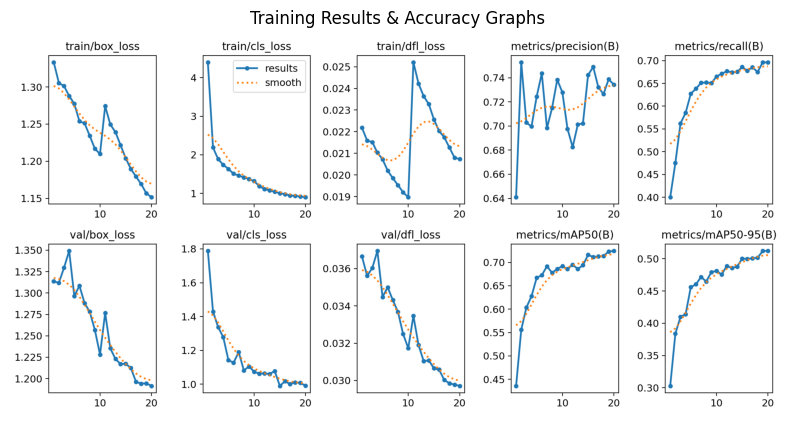

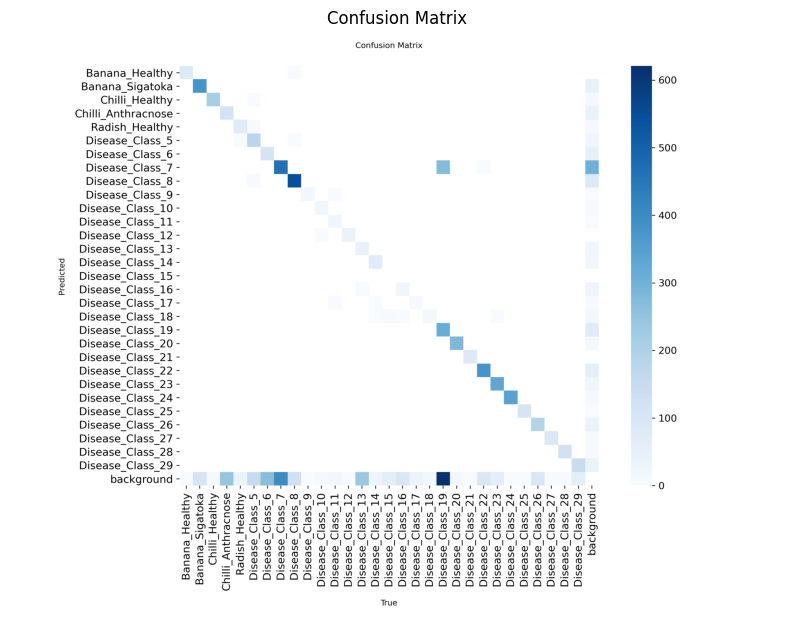

In [ ]:
import matplotlib.pyplot as plt
import cv2
import os


def show_metric(file_name, title):
    path = os.path.join('/content/runs/detect/train/', file_name)
    if os.path.exists(path):
        img = cv2.imread(path)
        img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
        plt.figure(figsize=(10, 8))
        plt.imshow(img)
        plt.title(title)
        plt.axis('off')
        plt.show()


show_metric('results.png', 'Training Results & Accuracy Graphs')


show_metric('confusion_matrix.png', 'Confusion Matrix')

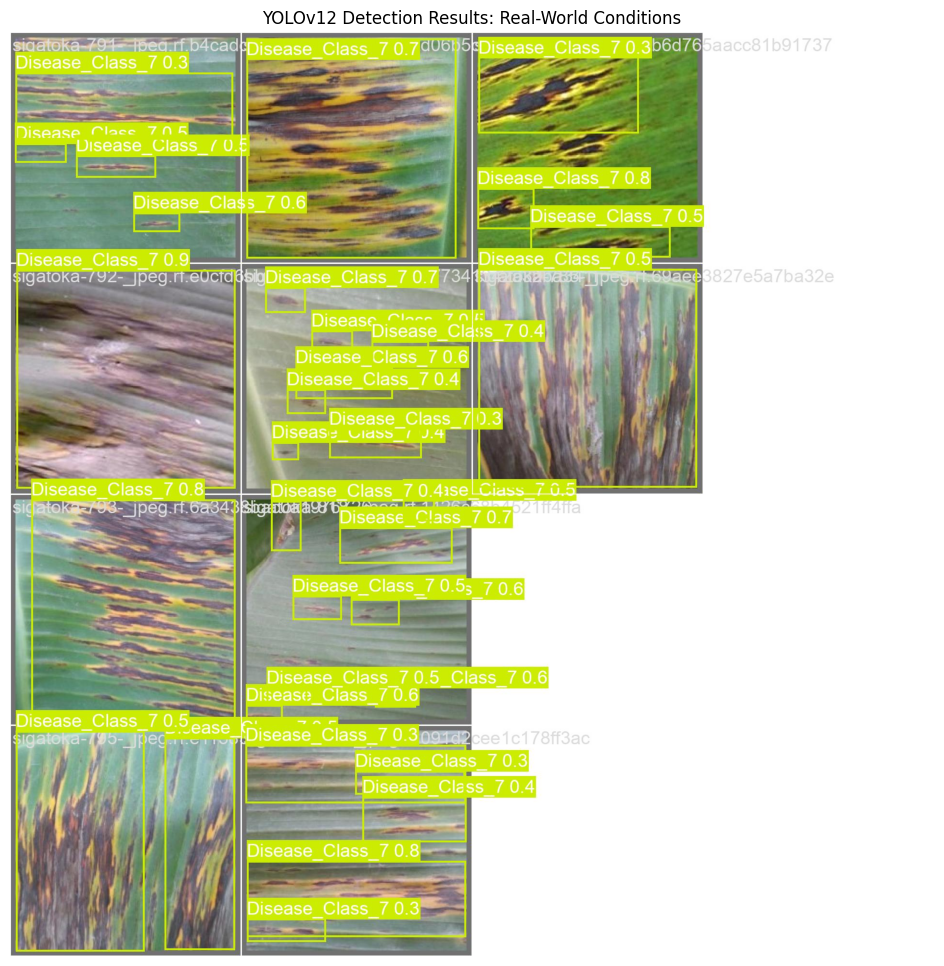

In [ ]:
import matplotlib.pyplot as plt
import cv2


prediction_path = '/content/runs/detect/train/val_batch0_pred.jpg'

if os.path.exists(prediction_path):
    img = cv2.imread(prediction_path)
    img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
    plt.figure(figsize=(15, 12))
    plt.imshow(img)
    plt.title("YOLOv12 Detection Results: Real-World Conditions")
    plt.axis('off')
    plt.show()
else:
    print("Epoch 20 hasn't finished yet, or the file is still being generated!")

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
import shutil
import os


drive_path = '/content/drive/MyDrive/Plantify_Project_2026'
os.makedirs(drive_path, exist_ok=True)


shutil.copy('/content/runs/detect/train/weights/best.pt', f'{drive_path}/plant_model_best.pt')
shutil.copy('/content/runs/detect/train/weights/last.pt', f'{drive_path}/plant_model_last.pt')

print(f" Model weights saved to: {drive_path}")

 Model weights saved to: /content/drive/MyDrive/Plantify_Project_2026


In [ ]:

!zip -r /content/plant_detection_results.zip /content/runs/detect/train


shutil.move('/content/plant_detection_results.zip', f'{drive_path}/plant_detection_results.zip')

print(f" All graphs, logs, and matrices saved as a ZIP to: {drive_path}")

  adding: content/runs/detect/train/ (stored 0%)
  adding: content/runs/detect/train/val_batch2_labels.jpg (deflated 13%)
  adding: content/runs/detect/train/BoxP_curve.png (deflated 9%)
  adding: content/runs/detect/train/train_batch1.jpg (deflated 9%)
  adding: content/runs/detect/train/results.png (deflated 7%)
  adding: content/runs/detect/train/val_batch0_pred.jpg (deflated 11%)
  adding: content/runs/detect/train/train_batch0.jpg (deflated 12%)
  adding: content/runs/detect/train/args.yaml (deflated 53%)
  adding: content/runs/detect/train/train_batch30621.jpg (deflated 13%)
  adding: content/runs/detect/train/val_batch0_labels.jpg (deflated 12%)
  adding: content/runs/detect/train/results.csv (deflated 60%)
  adding: content/runs/detect/train/val_batch1_pred.jpg (deflated 11%)
  adding: content/runs/detect/train/train_batch2.jpg (deflated 11%)
  adding: content/runs/detect/train/val_batch2_pred.jpg (deflated 13%)
  adding: content/runs/detect/train/BoxF1_curve.png (deflated 9%)
